## Functional preprocessing

### Loading libraries and data visualization

In [1]:
# downloading data and setup (data downloaded by Chri)
import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

####################
# DIPY_HOME should be set prior to import of dipy to make sure all downloads point to the right folder
####################
# os.environ["DIPY_HOME"] = "/home/jovyan/Data" # non sono sicura a cosa serva

#############################
# Loading fsl and freesurfer within Neurodesk
# You can find the list of available other modules by clicking on the "Softwares" tab on the left
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Load all relevant libraries for the lab 
# so all these libraries are imported from lab3 Idk if all of them are actually needed
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import mne_nirs
import nilearn
from nilearn.datasets import fetch_development_fmri

import mne
import mne_nirs


import xml.etree.ElementTree as ET
import os.path as op
import nibabel as nib
import glob

!pip install antspyx
import ants

import openneuro
from mne.datasets import sample
from mne_bids import BIDSPath, read_raw_bids, print_dir_tree, make_report


# Useful imports to define the direct download function below
import requests
import urllib.request
from tqdm import tqdm

# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json

In [2]:
%gui wx


(ipykernel_launcher.py:1170): dbind-WARNING **: 14:55:01.718: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1402404120/at-spi/bus_100: No such file or directory


In [3]:
#start FSLeyes
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

14:55:07: Debug: Adding duplicate image handler for 'Windows bitmap file'
14:55:07: Debug: Adding duplicate animation handler for '1' type
14:55:07: Debug: Adding duplicate animation handler for '2' type
14:55:07: Debug: Adding duplicate image handler for 'Windows bitmap file'
14:55:07: Debug: Adding duplicate animation handler for '1' type
14:55:07: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1170): Gtk-CRITICAL **: 14:55:07.821: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1170): Gtk-CRITICAL **: 14:55:09.990: gtk_window_resize: assertion 'width > 0' failed


In [ ]:
#visualizing fMRI data before all the preprocessing steps

fmri_path = os.path.join(notebook_dir,'fMRI','tfMRI_LANGUAGE_LR','tfMRI_LANGUAGE_LR.nii.gz')
derivatives = os.path.join(notebook_dir,'derivatives_func')

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(fmri_path)

### Motion correction

#### Throwing away first volumes for magnetic field 

Text(0, 0.5, 'Mean voxel intensity')

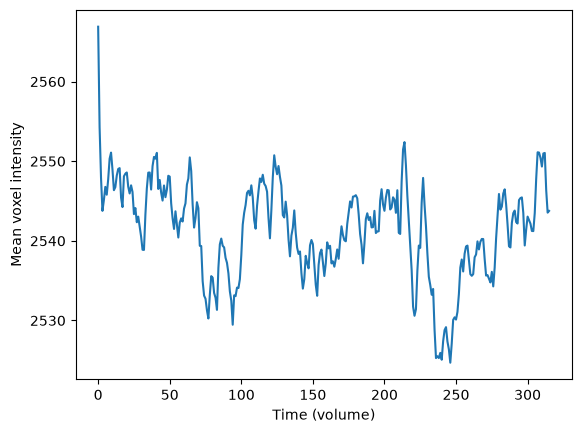

In [5]:
# check if there are some non stationary volumes at the beginning
import matplotlib.pyplot as plt
import nibabel as nib

plt.plot(nib.load(fmri_path).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

In [16]:
# Removing first volumes to make sure the magnetic field of the scanner is settled
file_to_trim = glob.glob(fmri_path)[0]
path_settled_fmri = op.join('derivatives_func','tfMRI_LANGUAGE_LR_settled.nii.gz')

start_vol = 5
n_tot = nib.load(fmri_path).shape[-1]
number_of_volumes = n_tot - start_vol # How many volumes should we keep?

# Function creating new nifti with trimmed number of volumes
fslroi(file_to_trim, path_settled_fmri, str(start_vol), str(number_of_volumes))
print(f"You kept {nib.load(path_settled_fmri).shape[-1]} volumes.")

You kept 311 volumes.


<Figure size 640x480 with 0 Axes>

In [17]:
# motion correction
from fsl.wrappers import mcflirt
path_moco_data = op.join('derivatives_func','tfMRI_LANGUAGE_LR_moco')
mcflirt(infile=path_settled_fmri,o=path_moco_data, plots=True, report=True, dof=6, mats=True)



Processed data will be saved as derivatives_func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [155] to 8 mm pixels
Registering volumes ... [156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][

refnum = 155
Original_refvol = -1


Registering volumes ... [156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][119][118][117][116][115][

{}

In [18]:
#visualizing moco
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(path_settled_fmri)
fsleyesDisplay.load(path_moco_data)


(ipykernel_launcher.py:1170): Gtk-WARNING **: 16:03:29.832: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1170): Gtk-WARNING **: 16:03:29.832: Negative content height -2 (allocation 8, extents 5x5) while allocating gadget (node button, owner GtkButton)


/tmp/ipykernel_1170/2755631542.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


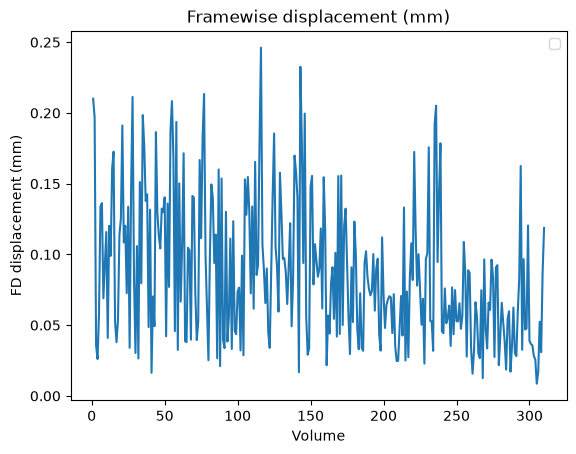

In [22]:
#visualizing framewise displacement
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(op.join('derivatives_func','tfMRI_LANGUAGE_LR_moco.par'))

def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    # To know this one, we can remember the definition of the radian!
    # Indeed, let the radian be theta, the arc length be s and the radius be r.
    # Then theta = s / r
    # We want to determine here s, for a sphere of 50mm radius and knowing theta. Easy enough!
    
    # Another way to think about it is through the line integral along the circle.
    # Integrating from 0 to theta with radius 50 will give you, unsurprisingly, r0 theta.
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
#plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.title("Framewise displacement (mm)")
plt.legend()
plt.show()


### Gaussian smoothing

In [ ]:
# gaussian smoothing

### Validate alignment between anatomical and functional data

In [ ]:
# validate alignment